Optimizando circuito... esto puede tomar unos segundos.

--- VALORES ÓPTIMOS ENCONTRADOS ---
Cc = 5.00e-12 F  (5.00 pF)
Rc = 3.26e+05 Ohms
Cz = 7.78e-13 F  (0.78 pF)
Margen de Fase (PM) = 48.60 grados
Frecuencia de cruce unitario = 2.17e+06 Hz
Ganancia DC (Aol) = 82.10 dB


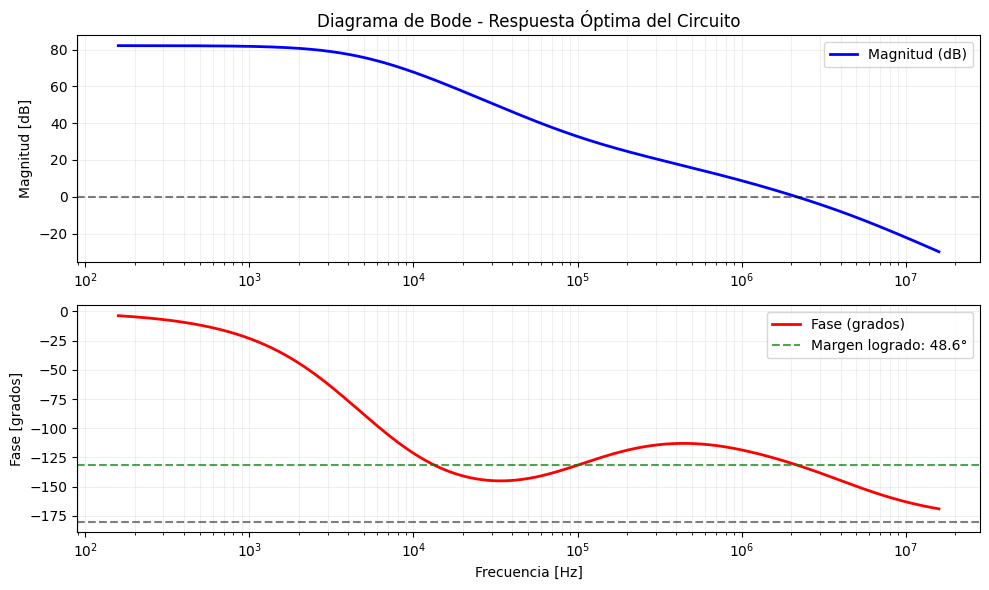

In [1]:
import sympy as sp
import numpy as np
from scipy import optimize
import scipy.signal as signal
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# 1. DEFINICIÓN SIMBÓLICA Y OBTENCIÓN DE LA FUNCIÓN DE TRANSFERENCIA
# ==============================================================================
s = sp.Symbol('s')
Vx = sp.Symbol('Vx')
Gm1, Gm2, Gmp = sp.symbols('Gm1 Gm2 Gmp')
Re1, Re2, Rc, Rpar = sp.symbols('Re1 Re2 Rc Rpar')
R3, R2 = sp.symbols('R3 R2')
Cc, Cggp, Cout, Cz = sp.symbols('Cc Cggp Cout Cz')
Va, Vb, Vout, Vy = sp.symbols('Va Vb Vout Vy')

# Ecuaciones de Nodos (KCL)
eq_Va = Gm1*Vx + Va/Re1 + (Va - Vb)/(Rc + 1/(s*Cc))
eq_Vb = Gm2*Va + Vb/Re2 + Vb*s*Cggp + (Vb - Va)/(Rc + 1/(s*Cc))
eq_Vout = Gmp*Vb + Vout/Rpar + Vout*s*Cout + (Vout - Vy)/R3 + (Vout - Vy)*s*Cz
eq_Vy = (Vy - Vout)/R3 + (Vy - Vout)*s*Cz + Vy/R2

# Resolver sistema y extraer numerador/denominador
sol = sp.solve((eq_Va, eq_Vb, eq_Vout, eq_Vy), (Va, Vb, Vout, Vy))
Hs = sp.simplify(sol[Vy] / Vx)
num, den = sp.fraction(Hs)

num_coeffs_sym = sp.Poly(num, s).all_coeffs()
den_coeffs_sym = sp.Poly(den, s).all_coeffs()

# Valores del circuito
fixed_vals = {
    Gm1: 463.89e-6, Gm2: 261.53e-6, Gmp: 301e-3,
    Re1: 110e3, Re2: 254e3, Rpar: 25,        
    Cout: 1e-6, Cggp: 9e-12,     
    R3: 109e3, R2: 109e3      
}

# Convertir expresiones simbólicas a funciones numéricas rápidas (para iterar miles de veces)
num_funcs = [sp.lambdify((Cc, Rc, Cz), c.subs(fixed_vals)) for c in num_coeffs_sym]
den_funcs = [sp.lambdify((Cc, Rc, Cz), c.subs(fixed_vals)) for c in den_coeffs_sym]

def get_sys(Cc_val, Rc_val, Cz_val):
    n = [float(f(Cc_val, Rc_val, Cz_val)) for f in num_funcs]
    d = [float(f(Cc_val, Rc_val, Cz_val)) for f in den_funcs]
    if d[-1] != 0 and (n[-1]/d[-1]) < 0:
        n = [-x for x in n] # Ajuste de signo para el margen de fase
    return signal.TransferFunction(n, d)

# ==============================================================================
# 2. LA FUNCIÓN OBJETIVO (O "FUNCIÓN DE COSTO") EXPLICADA PASO A PASO
# ==============================================================================
def objective(x):
    Cc_val, Rc_val, Cz_val = x
    sys = get_sys(Cc_val, Rc_val, Cz_val)
    w, mag, phase = signal.bode(sys, n=1000)
    
    crossings = np.where(np.diff(np.sign(mag)))[0]
    if len(crossings) == 0: 
        return 1e6 
    
    idx = crossings[-1] 
    w_c = np.interp(0, [mag[idx+1], mag[idx]], [w[idx+1], w[idx]])
    pm = np.interp(w_c, w, phase) + 180
    
    # --- NUEVA REGLA: CONTROL DEL VALLE ---
    # Extraemos todos los valores de fase que ocurren ANTES de la frecuencia de cruce
    fases_antes_de_cruce = phase[w < w_c]
    
    penalizacion_valle = 0
    if len(fases_antes_de_cruce) > 0:
        min_fase_valle = np.min(fases_antes_de_cruce)
        # Si el valle cae por debajo de -145 grados, aplicamos un castigo gigante.
        # Mientras más baje, más grande es la multa.
        if min_fase_valle < -145:
            penalizacion_valle = (abs(min_fase_valle) - 130) * 1000 

    # Cálculos de error normales
    error_fase = (pm - 80)**2 
    penalizacion_tamano = (Cc_val * 1e12)*1.0 + (Cz_val * 1e12)*0.1
    
    # Sumamos el castigo del valle al costo total
    return error_fase + penalizacion_tamano + penalizacion_valle
# ==============================================================================
# 3. EJECUCIÓN DE LA OPTIMIZACIÓN Y GRAFICACIÓN
# ==============================================================================
# Límites permitidos: Cc(1pF a 100pF), Rc(10Ω a 500kΩ), Cz(1pF a 500pF)
bounds = [(0.1e-12, 5e-12), (10, 500e3), (0.1e-12, 5e-12)]

print("Optimizando circuito... esto puede tomar unos segundos.")
result = optimize.differential_evolution(objective, bounds, popsize=20, maxiter=100, seed=42)

# Extraer los mejores valores encontrados
best_Cc, best_Rc, best_Cz = result.x

# Evaluar el sistema final óptimo para extraer sus métricas
sys_opt = get_sys(best_Cc, best_Rc, best_Cz)
w, mag, phase = signal.bode(sys_opt, n=2000)
crossings = np.where(np.diff(np.sign(mag)))[0]
pm_actual = 0
w_c = 0
if len(crossings) > 0:
    idx = crossings[-1]
    w_c = np.interp(0, [mag[idx+1], mag[idx]], [w[idx+1], w[idx]])
    pm_actual = np.interp(w_c, w, phase) + 180

print(f"\n--- VALORES ÓPTIMOS ENCONTRADOS ---")
print(f"Cc = {best_Cc:.2e} F  ({best_Cc*1e12:.2f} pF)")
print(f"Rc = {best_Rc:.2e} Ohms")
print(f"Cz = {best_Cz:.2e} F  ({best_Cz*1e12:.2f} pF)")
print(f"Margen de Fase (PM) = {pm_actual:.2f} grados")
print(f"Frecuencia de cruce unitario = {w_c/(2*np.pi):.2e} Hz")
print(f"Ganancia DC (Aol) = {mag[0]:.2f} dB")

# ----------------- FUNCIÓN DE GRAFICACIÓN -----------------
def plot_optimal_bode(w, mag, phase, pm_actual):
    plt.figure(figsize=(10, 6))
    
    # Gráfico de Magnitud
    plt.subplot(2, 1, 1)
    plt.semilogx(w/(2*np.pi), mag, label='Magnitud (dB)', color='b', linewidth=2)
    plt.axhline(0, color='k', linestyle='--', alpha=0.5)
    plt.ylabel('Magnitud [dB]')
    plt.title('Diagrama de Bode - Respuesta Óptima del Circuito')
    plt.grid(True, which="both", ls="-", alpha=0.2)
    plt.legend()

    # Gráfico de Fase
    plt.subplot(2, 1, 2)
    plt.semilogx(w/(2*np.pi), phase, label='Fase (grados)', color='r', linewidth=2)
    if pm_actual != 0:
        plt.axhline(pm_actual-180, color='g', linestyle='--', alpha=0.7, 
                    label=f'Margen logrado: {pm_actual:.1f}°')
    plt.axhline(-180, color='k', linestyle='--', alpha=0.5)
    plt.xlabel('Frecuencia [Hz]')
    plt.ylabel('Fase [grados]')
    plt.grid(True, which="both", ls="-", alpha=0.2)
    plt.legend()

    plt.tight_layout()
    plt.show() # Muestra la ventana interactiva en tu computadora

# Llamar a la graficadora
plot_optimal_bode(w, mag, phase, pm_actual)

--- RESULTADOS DE SIMULACIÓN ---
Ganancia DC: 88.02 dB
Frecuencia de cruce unitario: 3.29e+06 Hz
Margen de Fase (PM): 48.35 grados
Punto más bajo del valle (Fase mínima antes de fc): -146.57 grados


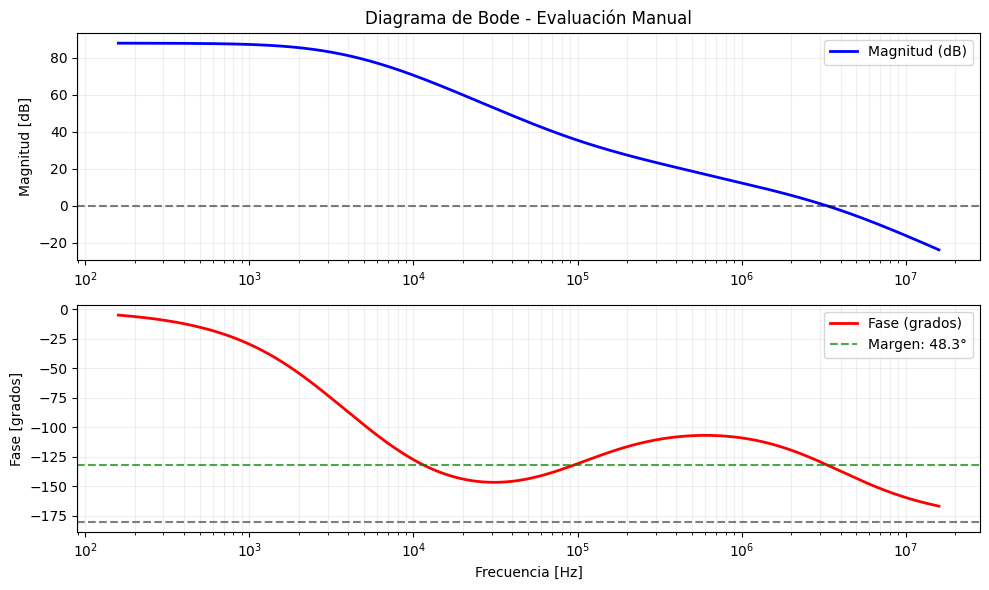

In [2]:
import sympy as sp
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt

# ==============================================================================
# 1. DEFINICIÓN DEL SISTEMA
# ==============================================================================
s = sp.Symbol('s')
Vx = sp.Symbol('Vx')
Gm1, Gm2, Gmp = sp.symbols('Gm1 Gm2 Gmp')
Re1, Re2, Rc, Rpar = sp.symbols('Re1 Re2 Rc Rpar')
R3, R2 = sp.symbols('R3 R2')
Cc, Cggp, Cout, Cz = sp.symbols('Cc Cggp Cout Cz')
Va, Vb, Vout, Vy = sp.symbols('Va Vb Vout Vy')

# Ecuaciones de Nodos (KCL)
eq_Va = Gm1*Vx + Va/Re1 + (Va - Vb)/(Rc + 1/(s*Cc))
eq_Vb = Gm2*Va + Vb/Re2 + Vb*s*Cggp + (Vb - Va)/(Rc + 1/(s*Cc))
eq_Vout = Gmp*Vb + Vout/Rpar + Vout*s*Cout + (Vout - Vy)/R3 + (Vout - Vy)*s*Cz
eq_Vy = (Vy - Vout)/R3 + (Vy - Vout)*s*Cz + Vy/R2

# Resolver sistema y extraer función de transferencia
sol = sp.solve((eq_Va, eq_Vb, eq_Vout, eq_Vy), (Va, Vb, Vout, Vy))
Hs = sp.simplify(sol[Vy] / Vx)

# ==============================================================================
# 2. INGRESO DE VALORES MANUALES (¡Modifica esto!)
# ==============================================================================
valores_usuario = {
    Gm1: 600e-6, Gm2: 400e-6, Gmp: 301e-3,
    Re1: 110e3, Re2: 254e3, Rpar: 25,        
    Cout: 1e-6, Cggp: 9e-12,     
    R3: 109e3, R2: 109e3 ,
    
    # Valores de la red de compensación a probar
    Cc: 5e-12,     # 5.2 pF
    Rc: 326e3,       # 113 kOhms
    Cz: 0.78e-12       # 30 pF
}

# ==============================================================================
# 3. EVALUACIÓN Y GRÁFICAS
# ==============================================================================
# Sustituir valores y obtener polinomios
Hs_num = sp.simplify(Hs.subs(valores_usuario))
num, den = sp.fraction(Hs_num)

num_coeffs = [float(c) for c in sp.Poly(num, s).all_coeffs()]
den_coeffs = [float(c) for c in sp.Poly(den, s).all_coeffs()]

# Ajuste de fase para sistemas de realimentación negativa
if den_coeffs[-1] != 0 and (num_coeffs[-1]/den_coeffs[-1]) < 0:
    num_coeffs = [-x for x in num_coeffs]

# Crear sistema y calcular Bode
sys = signal.TransferFunction(num_coeffs, den_coeffs)
w, mag, phase = signal.bode(sys, n=2000)

# Calcular métricas
crossings = np.where(np.diff(np.sign(mag)))[0]
pm_actual = 0
w_c = 0
min_valle = 0

if len(crossings) > 0:
    idx = crossings[-1]
    w_c = np.interp(0, [mag[idx+1], mag[idx]], [w[idx+1], w[idx]])
    pm_actual = np.interp(w_c, w, phase) + 180
    fases_antes = phase[w < w_c]
    if len(fases_antes) > 0:
        min_valle = np.min(fases_antes)

print(f"--- RESULTADOS DE SIMULACIÓN ---")
print(f"Ganancia DC: {mag[0]:.2f} dB")
if w_c > 0:
    print(f"Frecuencia de cruce unitario: {w_c/(2*np.pi):.2e} Hz")
    print(f"Margen de Fase (PM): {pm_actual:.2f} grados")
    print(f"Punto más bajo del valle (Fase mínima antes de fc): {min_valle:.2f} grados")
else:
    print("El sistema no cruza los 0 dB.")

# Graficar
plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
plt.semilogx(w/(2*np.pi), mag, label='Magnitud (dB)', color='b', linewidth=2)
plt.axhline(0, color='k', linestyle='--', alpha=0.5)
plt.ylabel('Magnitud [dB]')
plt.title('Diagrama de Bode - Evaluación Manual')
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.legend()

plt.subplot(2, 1, 2)
plt.semilogx(w/(2*np.pi), phase, label='Fase (grados)', color='r', linewidth=2)
if w_c > 0:
    plt.axhline(pm_actual-180, color='g', linestyle='--', alpha=0.7, label=f'Margen: {pm_actual:.1f}°')
plt.axhline(-180, color='k', linestyle='--', alpha=0.5)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Fase [grados]')
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
import site
import sys
import subprocess

# 1. Registrar la ruta de paquetes del usuario en el sistema
user_site = '/headless/.local/lib/python3.12/site-packages'
site.addsitedir(user_site)

# 2. Intentar importar; si falla, instalarlo automáticamente
try:
    from PyLTSpice import RawRead
    print("¡PyLTSpice ya estaba instalado y listo para usar!")
except ImportError:
    print("PyLTSpice no fue encontrado. Instalando automáticamente...")
    
    # Ejecuta pip install dentro del mismo Kernel de Python
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--user", "PyLTSpice"])
    
    # Re-asegurar que la ruta esté cargada
    site.addsitedir(user_site)
    
    # Importación tras la instalación
    from PyLTSpice import RawRead
    print("¡PyLTSpice se instaló e importó correctamente!")

¡PyLTSpice ya estaba instalado y listo para usar!


In [12]:
from PyLTSpice import RawRead
print("PyLTSpice importado correctamente")

PyLTSpice importado correctamente


In [ ]:
import re
import os
import subprocess
from PyLTSpice import RawRead

parametros_ldo = {}
graficas_ldo = {}

def one_pvt1hilo(netlist_path, temp, vdd, proces):
    print(f"Ejecutando corner: temperatura = {temp}, VDD = {vdd}, Proceso = {proces}")
    
    # 1. Extraemos la carpeta original donde vive el .spice
    directorio_sim = os.path.dirname(netlist_path)
    
    # 2. Leer y modificar el netlist
    with open(netlist_path, 'r') as archivo:
        contenido = archivo.read()

    patron_corner = r"(\.lib\s+/foss/pdks/sky130A/libs\.tech/ngspice/sky130\.lib\.spice\s+)\w+"
    contenido = re.sub(patron_corner, rf"\g<1>{proces}", contenido)
    
    patron_temp = r"(\.option\s+temp=)[-\d\.]+"
    contenido = re.sub(patron_temp, rf"\g<1>{temp}", contenido)
    
    patron_vdd = r"(\.param\s+VDD\s*=\s*)[-\d\.]+"
    contenido = re.sub(patron_vdd, rf"\g<1>{vdd}", contenido)
    
    with open(netlist_path, 'w') as archivo:
        archivo.write(contenido)

    # 3. Simular forzando a Ngspice a quedarse en su carpeta natural
    comando = ['/foss/tools/ngspice/bin/ngspice', "-b", netlist_path]
    resultado = subprocess.run(comando, capture_output=True, text=True, cwd=directorio_sim)
    
    if resultado.returncode != 0:
        print("La simulación falló. Aquí está el error de Ngspice:\n")
        print(resultado.stderr)
        return
    
    # 4. Extraer el LOG
    mi_log = resultado.stdout
    patron = r"([a-zA-Z0-9_]+)\s*=\s*([+-]?\d+\.?\d*[eE]?[+-]?\d*)"
    coincidencias = re.findall(patron, mi_log)
    
    nombre_llave = f"{vdd}[V]_{temp}[C]_{proces}"
    
    parametros_ldo[nombre_llave] = {}
    graficas_ldo[nombre_llave] = {}

    for nombre, valor in coincidencias:
        parametros_ldo[nombre_llave][nombre.strip().lower()] = float(valor)
    
    if "tnom" in parametros_ldo[nombre_llave]:
        del parametros_ldo[nombre_llave]["tnom"]

    # 5. Extraer vectores apuntando al mismo directorio_sim (donde cayeron los .raw)
    raw_tran = RawRead(os.path.join(directorio_sim, "LDO_tran_picos.raw"))
    raw_ac_stability = RawRead(os.path.join(directorio_sim, "LDO_ac_estability.raw"))
    raw_ac_psrr = RawRead(os.path.join(directorio_sim, "LDO_ac_psrr.raw"))
    raw_dc_line = RawRead(os.path.join(directorio_sim, "LDO_dc_line.raw"))
    raw_dc_load = RawRead(os.path.join(directorio_sim, "LDO_dc_load.raw"))
    
    graficas_ldo[nombre_llave]["time"] = raw_tran.get_trace("time").get_wave()
    graficas_ldo[nombre_llave]["t_vo"] = raw_tran.get_trace("v(vo)").get_wave()
    
    graficas_ldo[nombre_llave]["frecuencia"] = raw_ac_stability.get_trace("frequency").get_wave()
    graficas_ldo[nombre_llave]["fase"] = raw_ac_stability.get_trace("fase_deg").get_wave()
    graficas_ldo[nombre_llave]["ganancia"] = raw_ac_stability.get_trace("loop_gain_db").get_wave()
    
    graficas_ldo[nombre_llave]["psrr"] = raw_ac_psrr.get_trace("psrr_db").get_wave()
    
    graficas_ldo[nombre_llave]["dc_vin"] = raw_dc_line.get_trace("v(v-sweep)").get_wave()
    graficas_ldo[nombre_llave]["dc_vin_vo"] = raw_dc_line.get_trace("v(vo)").get_wave()
    
    graficas_ldo[nombre_llave]["dc_iload"] = raw_dc_load.get_trace("i(i-sweep)").get_wave()
    graficas_ldo[nombre_llave]["dc_iload_vo"] = raw_dc_load.get_trace("v(vo)").get_wave()
    
    print("¡Extracción completada!")


# ==============================================================================
# BUCLE DE EJECUCIÓN
# ==============================================================================
temperaturas = [-40, 27, 125]
voltajes = [1.62, 1.8, 1.98] 
corners_proceso = [
    "tt", "sf", "ff", "ss", "fs", "ll", "hh", "hl", "lh",
    "sf_ll", "sf_hh", "sf_hl", "sf_lh", "ff_ll", "ff_hh", "ff_hl", "ff_lh",
    "ss_ll", "ss_hh", "ss_hl", "ss_lh", "fs_ll", "fs_hh", "fs_hl", "fs_lh"
]

netlist_path = "/headless/.xschem/simulations/ldo_tb.spice"

total_sim = len(temperaturas) * len(voltajes) * len(corners_proceso)
contador = 1

print(f"Iniciando barrido secuencial PVT: {total_sim} simulaciones programadas.\n")

for temp in temperaturas:
    for vdd in voltajes:
        for proces in corners_proceso:
            print(f"--- Progreso: {contador}/{total_sim} ---")
            
            # Ya no pasamos raw_path, la función se encarga de todo
            one_pvt1hilo(netlist_path, temp, vdd, proces)
            
            contador += 1

print("\n¡Barrido masivo finalizado con éxito!")